<a href="https://colab.research.google.com/github/nhahub/NHA-5-153/blob/main/notebooks/04_statistical_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 2 · Task 1: Statistical Analysis & Hypothesis Testing

**Goal:** test, with formal statistics, whether **salary, performance rating, job role** (plus tenure, age and gender)
are related to **attrition**, and draft the statistical findings for the Data Analysis Report.

**Data:** `employee_attriton_data_clean.csv`, using **original units** (not the min-max-scaled file), so differences can
be read directly (for example "leavers earn 204 less per month").

| # | Question | Test(s) |
|---|---|---|
| 0 | Are parametric assumptions met? | D'Agostino K², Levene, Q-Q plots |
| 1 | Do leavers and stayers differ on numeric features? | **Welch t-test**, Mann-Whitney U, Cohen's d |
| 2 | Is attrition independent of categorical features? | **Chi-square**, Cramér's V, adjusted residuals |
| 3 | Is there a monotonic trend over ordinal levels? | Cochran-Armitage trend test |
| 4 | Do salary/tenure differ across roles and ratings? Do the attrition gaps depend on them? | **One-way & two-way ANOVA**, Kruskal-Wallis, Tukey HSD |
| 5 | Is the salary effect consistent within every role / rating? | Stratified Welch t-tests |
| 6 | Which features matter **after controlling for the others**? | Multivariable logistic regression, likelihood-ratio tests |

**Conventions:** α = 0.05 · all p-values within each test family are **Holm-corrected** · every test reports an **effect size**.
With n = 49,000, even tiny differences come out "significant", so the effect size tells us whether a difference matters in practice.

> All computations live in `src/statistical_analysis.py` (run `python src/statistical_analysis.py` to regenerate
> `reports/milestone2/`). This notebook calls the same functions and interprets the output.

## Setup

In [1]:
import sys, os
from pathlib import Path

# On Colab: clone the repo so the src/ modules and data are available
if "google.colab" in sys.modules and not Path("NHA-5-153").exists():
    !git clone -q https://github.com/nhahub/NHA-5-153.git
    !pip install -q statsmodels
    os.chdir("NHA-5-153")
elif Path.cwd().name == "notebooks":
    os.chdir("..")

sys.path.insert(0, "src")
import numpy as np
import pandas as pd
from IPython.display import Image, display

import statistical_analysis as sa
from eda_pipeline import DATA_PATH, add_eda_features

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 30)
sa.FIG_DIR.mkdir(parents=True, exist_ok=True)
sa.TAB_DIR.mkdir(parents=True, exist_ok=True)

df = add_eda_features(pd.read_csv(DATA_PATH))
print(df.shape)
df[["Age", "Gender", "JobRole", "TenureYears", "PerformanceRating", "MonthlySalary", "Attrition"]].head()

(49000, 13)


,Age,Gender,JobRole,TenureYears,PerformanceRating,MonthlySalary,Attrition
0,33.0000,Female,Manager,1.0000,1.0000,"9,734.5100",No
1,33.0000,Female,HR Specialist,5.0000,4.0000,"7,552.3800",No
2,45.0000,Male,Manager,0.0000,4.0000,"3,931.6300",No
3,35.0000,Non-Binary,Manager,2.0000,3.0000,"7,992.2600",No
4,42.0000,Male,Manager,1.0000,3.0000,"5,215.6000",Yes


### Hypotheses
For each feature *X*:
- **H₀:** *X* is not associated with attrition (equal means / distributions for leavers and stayers, or independence in the contingency table).
- **H₁:** *X* is associated with attrition.

## 0. Assumption checks

In [2]:
checks = sa.assumption_checks(df)
checks[["Feature", "Group", "n", "Skew", "Kurtosis", "Normality_p", "Levene_p"]]

  [tab] 00_assumption_checks.csv


  [fig] 00_qq_plots.png


,Feature,Group,n,Skew,Kurtosis,Normality_p,Levene_p
0,MonthlySalary,No,36470,0.0389,-0.0138,0.0087,0.3284
1,MonthlySalary,Yes,12530,0.0262,-0.0347,0.3579,0.3284
2,PerformanceRating,No,36470,0.0336,0.1311,0.0000,0.0015
3,PerformanceRating,Yes,12530,0.0675,-0.0085,0.0086,0.0015
4,TenureYears,No,36470,1.9504,5.6686,0.0000,0.0000
5,TenureYears,Yes,12530,1.9932,7.2371,0.0000,0.0000
6,Age,No,36470,0.5002,0.5210,0.0000,0.0000
7,Age,Yes,12530,0.4799,0.4354,0.0000,0.0000
8,Salary_Performance_Ratio,No,36470,2.3966,8.6723,0.0000,0.0000
9,Salary_Performance_Ratio,Yes,12530,2.4789,10.4753,0.0000,0.0000


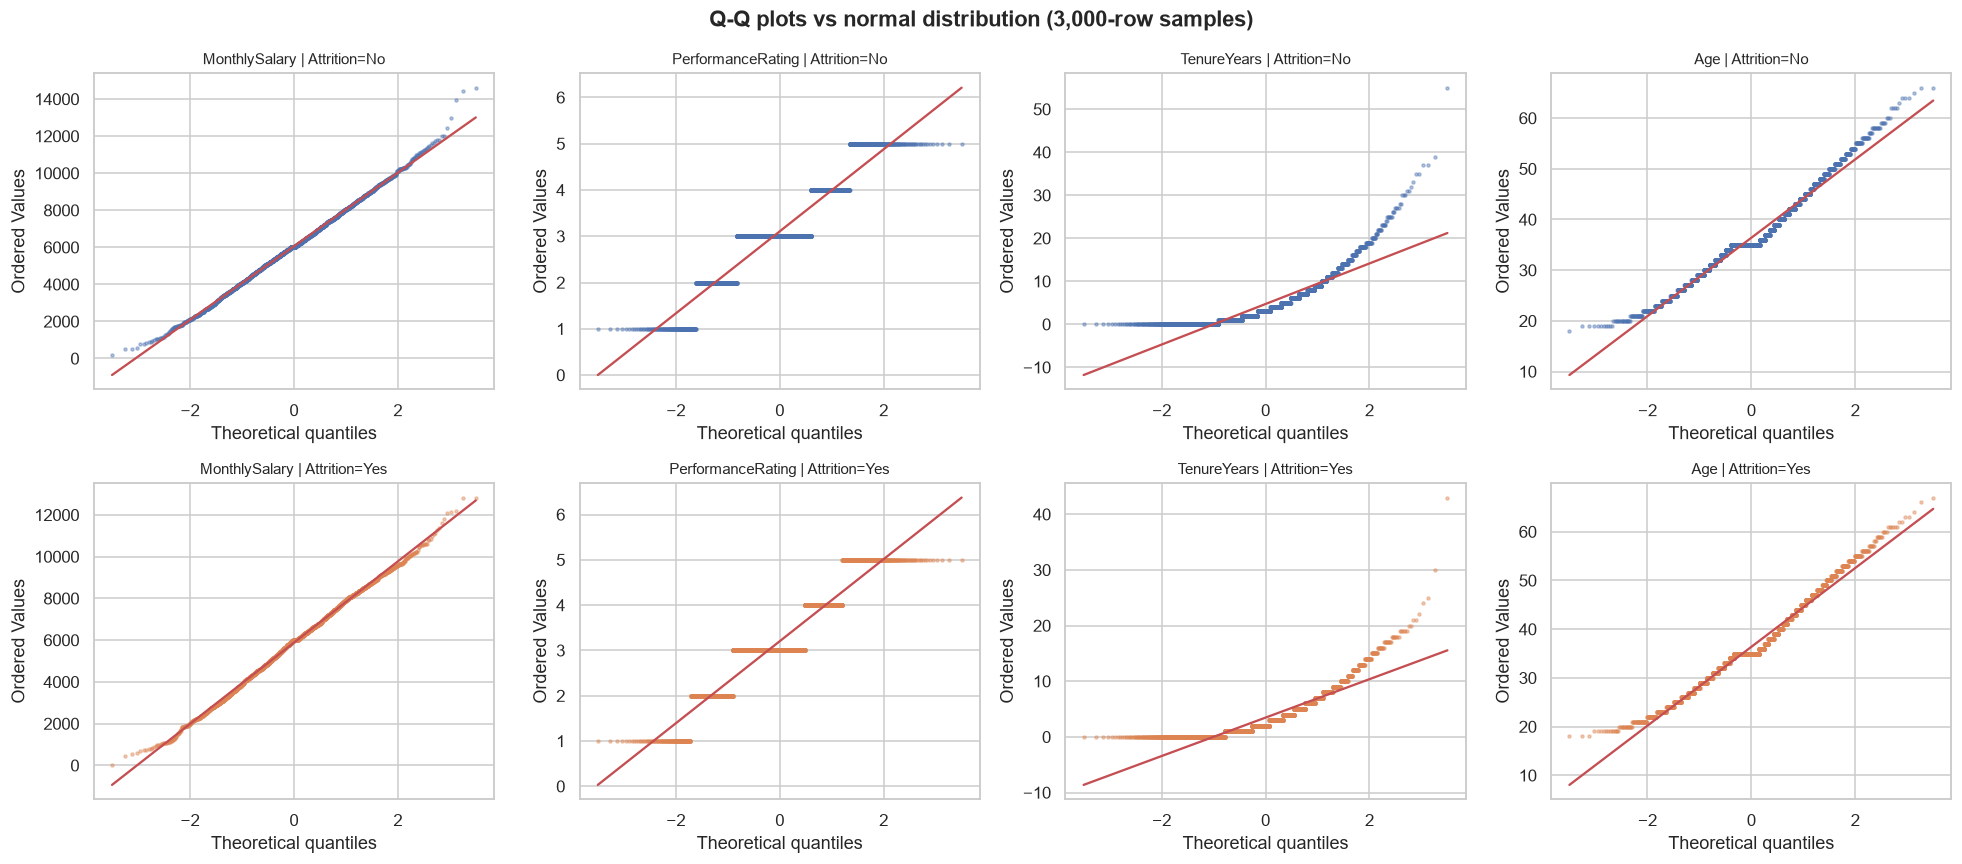

In [3]:
display(Image(str(sa.FIG_DIR / "00_qq_plots.png")))

**Interpretation**
- **MonthlySalary** is close to normal (skew ≈ 0.03) and its variances are equal (Levene p = 0.33), so the t-test is fully appropriate.
- **TenureYears** (skew ≈ 2.0) and **Age** are clearly non-normal, with unequal variances (Levene p < 0.001).
- **Decision:** use **Welch's t-test**, which doesn't assume equal variances and is robust to non-normality at this sample
  size (central limit theorem), together with the non-parametric **Mann-Whitney U** test as a robustness check. A feature
  counts as significant only if **both** tests agree.

## 1. Numeric features: Welch t-test & Mann-Whitney U

In [4]:
num = sa.numeric_tests(df)
num[["Feature", "Mean_Stayed", "Mean_Left", "MeanDiff_(Left-Stayed)", "CI95_low", "CI95_high",
     "Welch_t", "Welch_p_holm", "MannWhitney_p_holm", "Cohens_d", "Effect", "Reject_H0"]]

  [tab] 01_numeric_ttest_mannwhitney.csv


  [fig] 01_effect_sizes_cohens_d.png


,Feature,Mean_Stayed,Mean_Left,MeanDiff_(Left-Stayed),CI95_low,CI95_high,Welch_t,Welch_p_holm,MannWhitney_p_holm,Cohens_d,Effect,Reject_H0
0,MonthlySalary,"6,051.3538","5,847.5447",-203.8091,-243.3322,-164.2860,-10.1075,0.0000,0.0000,-0.1042,negligible,True
1,PerformanceRating,3.1220,3.2236,0.1016,0.0822,0.1209,10.2900,0.0000,0.0000,0.1069,negligible,True
2,TenureYears,4.8498,3.5640,-1.2858,-1.3728,-1.1989,-28.9905,0.0000,0.0000,-0.2601,small,True
3,Age,36.3040,36.1877,-0.1163,-0.2772,0.0447,-1.4159,0.1568,0.0776,-0.0148,negligible,False
4,Salary_Performance_Ratio,"2,205.4102","2,034.4512",-170.9589,-195.1200,-146.7978,-13.8690,0.0000,0.0000,-0.1357,negligible,True


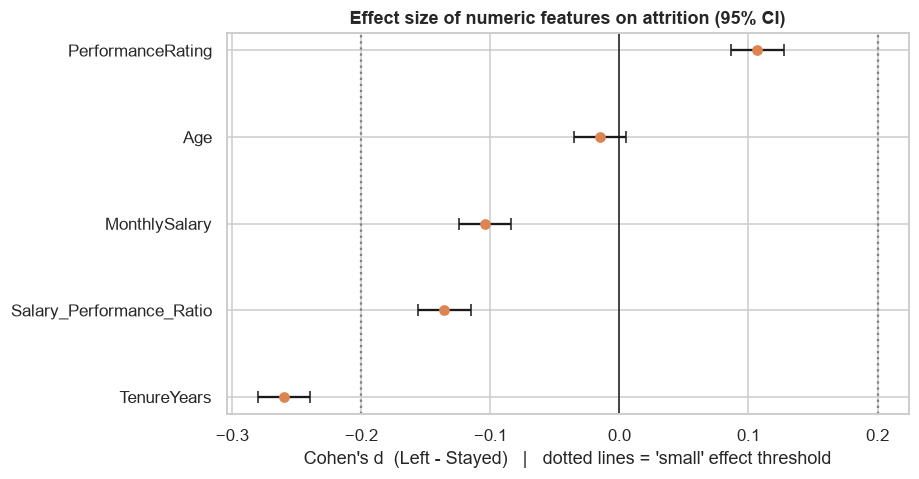

In [5]:
display(Image(str(sa.FIG_DIR / "01_effect_sizes_cohens_d.png")))

**Interpretation**

| Feature | Result | Effect |
|---|---|---|
| **TenureYears** | Leavers have **1.29 fewer years** of tenure (95 % CI 1.20–1.37), p < 0.001 | **small** (d = −0.26), the largest effect |
| **MonthlySalary** | Leavers earn **204 less per month** (95 % CI 164–243), p < 0.001 | negligible (d = −0.10) |
| **PerformanceRating** | Leavers are rated **0.10 points higher** (95 % CI 0.08–0.12), p < 0.001 | negligible (d = +0.11) |
| Salary / Performance ratio | Leavers get **less pay per rating point** (−171), p < 0.001 | negligible (d = −0.14) |
| Age | No difference (−0.12 yrs, CI includes 0), p = 0.16 | none |

→ **Reject H₀** for tenure, salary and performance. **Fail to reject** for age.
Leavers are **newer, slightly lower-paid, and slightly better-rated** than stayers.

## 2. Categorical features: chi-square test of independence

In [6]:
chi = sa.chi_square_tests(df)
chi[["Feature", "Levels", "Chi2", "dof", "p_holm", "Cramers_V", "Effect", "MinRate_%", "MaxRate_%",
     "HighestRisk_Level", "Expected>=5", "Reject_H0"]]

  [tab] 02_chi_square_tests.csv
  [tab] 02_chi_square_adjusted_residuals.csv


  [fig] 02_chi_square_residuals.png


,Feature,Levels,Chi2,dof,p_holm,Cramers_V,Effect,MinRate_%,MaxRate_%,HighestRisk_Level,Expected>=5,Reject_H0
0,JobRole,5,0.2460,4,1.0000,0.0022,negligible,25.4276,25.7273,HR Specialist,True,False
1,Gender,3,1.0989,2,1.0000,0.0047,negligible,25.4725,26.4986,Non-Binary,True,False
2,PerformanceRating,5,110.6249,4,0.0000,0.0475,negligible,20.5808,30.2301,5.0,True,True
3,TenureGroup,4,564.8084,3,0.0000,0.1074,small,14.2195,29.2128,0-2 yrs,True,True
4,SalaryBand,4,99.5812,3,0.0000,0.0451,negligible,22.6122,28.0653,Low,True,True
5,AgeGroup,5,16.7886,4,0.0064,0.0185,negligible,24.7821,27.5432,18-25,True,True


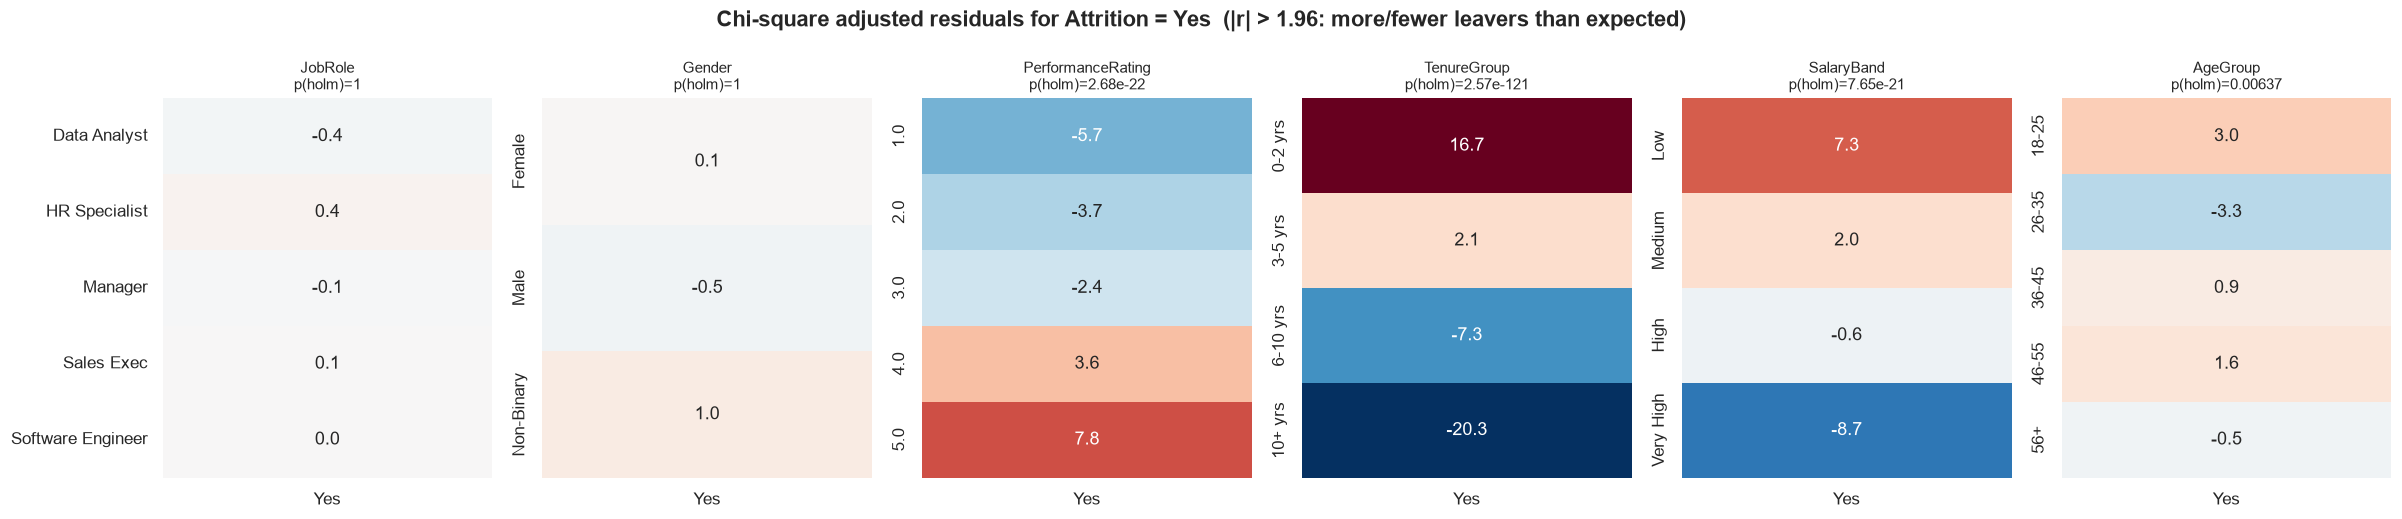

In [7]:
display(Image(str(sa.FIG_DIR / "02_chi_square_residuals.png")))

**Interpretation**
- **JobRole: no association** (χ² = 0.25, dof = 4, p_holm = 1.0, V = 0.002). Attrition is 25.4 %–25.7 % in every role,
  and no adjusted residual comes close to ±1.96. **Fail to reject H₀.**
- **Gender: no association** (χ² = 1.10, p_holm = 1.0). **Fail to reject H₀.**
- **PerformanceRating: significant** (χ² = 110.6, p < 0.001). The residuals switch from **negative at ratings 1-3** to
  **positive at 4-5** (+7.8 at rating 5), meaning there are more high-performer leavers than independence would predict.
- **TenureGroup** has the strongest association (χ² = 564.8, V = 0.107, *small*): +16.7 residual at 0-2 years, −20.3 at 10+ years.
- **SalaryBand: significant** (χ² = 99.6): more leavers than expected in the Low band (+7.3), fewer in Very High (−8.7).
- The validity condition holds: every expected cell count is ≥ 5 (the minimum is 205).

### 2b. Trend test for ordinal features (Cochran-Armitage)

In [8]:
sa.trend_test(df)

  [tab] 03_trend_tests.csv


,Feature,Trend_r,M2_chi2(1),p_value,Direction,p_holm
0,PerformanceRating,0.0466,106.2893,0.0000,increasing,0.0000
1,TenureGroup,-0.1036,526.1383,0.0000,decreasing,0.0000
2,SalaryBand,-0.0442,95.8564,0.0000,decreasing,0.0000


The chi-square test ignores the order of the levels. The trend test confirms the effects are **monotonic**: attrition
**rises** steadily with performance rating and **falls** steadily with tenure group and salary band (all p < 0.001).

## 3. ANOVA

### 3a. One-way ANOVA (with Kruskal-Wallis as a non-parametric check)

In [9]:
anova = sa.anova_tests(df)
anova["04_oneway_anova"][["Question", "F", "p_holm", "eta_sq", "Effect", "KW_p_holm",
                          "GroupMean_min", "GroupMean_max"]]

  [tab] 04_oneway_anova.csv
  [tab] 05_twoway_anova_salary_role_attrition.csv
  [tab] 06_twoway_anova_salary_perf_attrition.csv
  [tab] 07_tukey_salary_by_performance.csv


  [fig] 03_anova_interaction_plots.png


  [fig] 04_salary_by_performance_anova.png


,Question,F,p_holm,eta_sq,Effect,KW_p_holm,GroupMean_min,GroupMean_max
0,Is salary different across job roles?,0.2394,1.0000,0.0000,negligible,1.0000,"5,987.5139","6,011.7992"
1,Is pay linked to performance?,0.6748,1.0000,0.0001,negligible,1.0000,"5,944.8441","6,008.2540"
2,Is tenure different across job roles?,0.6421,1.0000,0.0001,negligible,1.0000,4.4719,4.5683
3,Is tenure linked to performance?,0.8700,1.0000,0.0001,negligible,1.0000,4.5052,4.7016


**Interpretation: an important negative result**
- **Salary does not differ by job role** (F = 0.24, p_holm = 1.0). A Manager earns the same on average as a Data Analyst.
- **Salary does not depend on performance rating** (F = 0.67, p_holm = 1.0, η² ≈ 0). Tukey HSD (below) finds **no
  pair** of ratings with different pay.
- Tenure does not differ by role or by rating either.

→ **Pay is not linked to performance in this organisation.** A rating-5 employee earns the same as a rating-1 employee.
This is the most likely explanation for why **high performers leave more** (Section 2): they are not rewarded for performing well.

In [10]:
anova["07_tukey_salary_by_performance"]

,group1,group2,meandiff,p-adj,lower,upper,reject
0,1.0,2.0,39.2152,0.9160,-87.1656,165.5960,False
1,1.0,3.0,60.3009,0.6050,-54.3319,174.9337,False
2,1.0,4.0,63.4099,0.6186,-58.9164,185.7361,False
3,1.0,5.0,55.1304,0.7950,-78.9118,189.1726,False
4,2.0,3.0,21.0857,0.9293,-50.3951,92.5666,False
5,2.0,4.0,24.1947,0.9328,-59.0672,107.4566,False
6,2.0,5.0,15.9152,0.9925,-83.7649,115.5954,False
7,3.0,4.0,3.1090,0.9999,-60.9310,67.1489,False
8,3.0,5.0,-5.1705,0.9998,-89.4599,79.1189,False
9,4.0,5.0,-8.2795,0.9993,-102.7662,86.2073,False


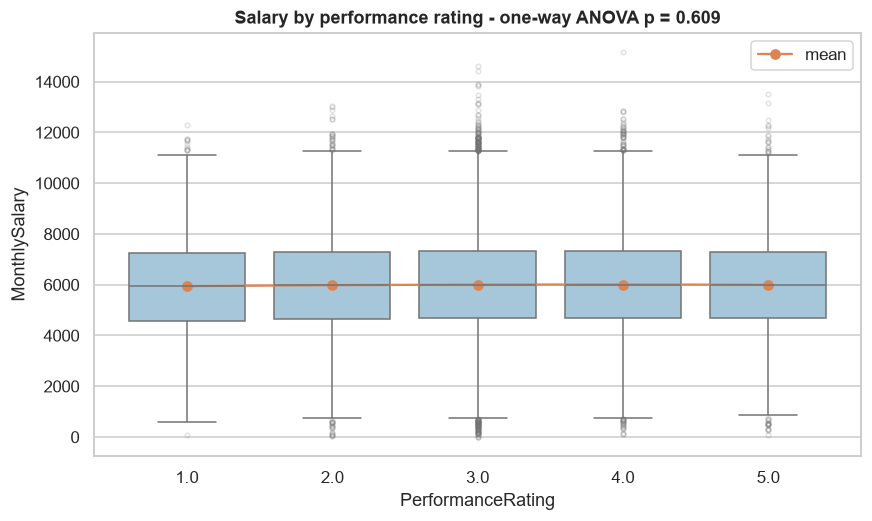

In [11]:
display(Image(str(sa.FIG_DIR / "04_salary_by_performance_anova.png")))

### 3b. Two-way ANOVA: does the salary gap between leavers and stayers depend on role or performance?

In [12]:
anova["05_twoway_anova_salary_role_attrition"]

,sum_sq,df,F,PR(>F),eta_sq,partial_eta_sq,omega_sq
C(JobRole),"3,565,499.0537",4.0000,0.2331,0.9199,0.0000,0.0000,-0.0001
C(Attrition),"387,276,698.5093",1.0000,101.2570,0.0000,0.0021,0.0021,0.0020
C(JobRole):C(Attrition),"1,968,322.5926",4.0000,0.1287,0.9721,0.0000,0.0000,-0.0001
Residual,"187,371,551,183.5192","48,990.0000",NaN,NaN,NaN,NaN,NaN


In [13]:
anova["06_twoway_anova_salary_perf_attrition"]

,sum_sq,df,F,PR(>F),eta_sq,partial_eta_sq,omega_sq
C(PerformanceRating),"14,937,753.0093",4.0000,0.9767,0.4188,0.0001,0.0001,-0.0000
C(Attrition),"391,975,076.9501",1.0000,102.5138,0.0000,0.0021,0.0021,0.0021
C(PerformanceRating):C(Attrition),"42,381,177.0139",4.0000,2.7710,0.0256,0.0002,0.0002,0.0001
Residual,"187,319,766,075.1422","48,990.0000",NaN,NaN,NaN,NaN,NaN


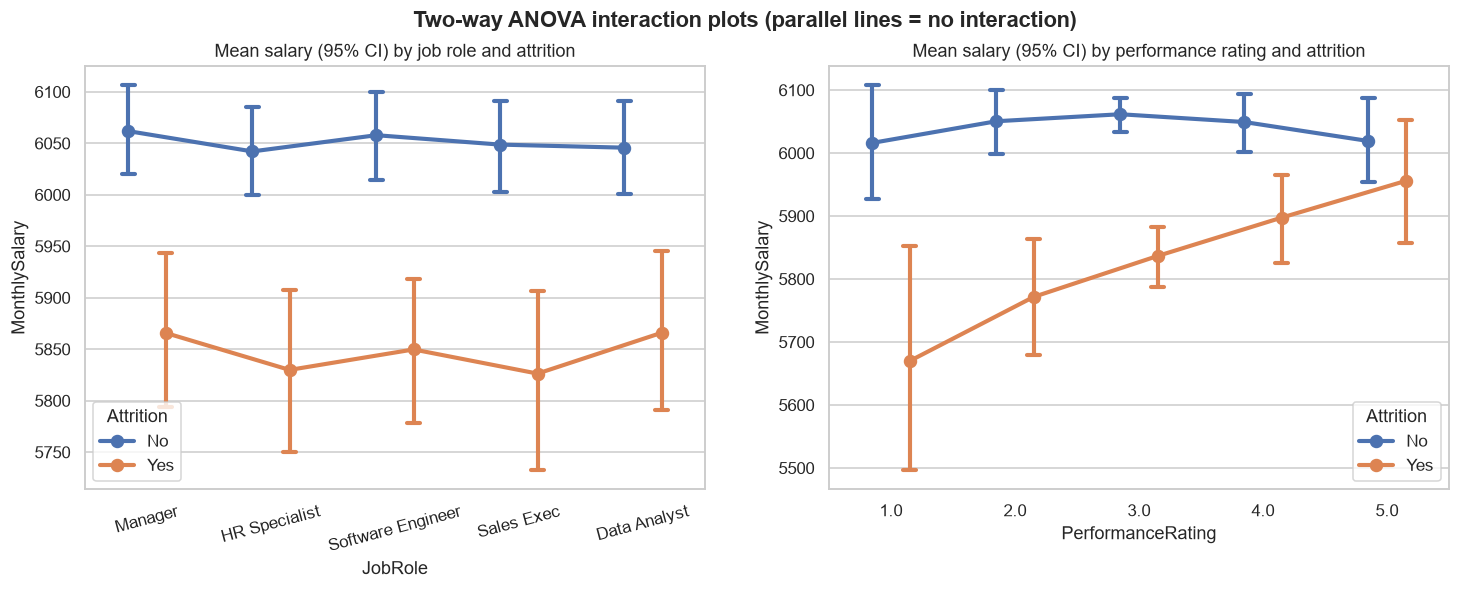

In [14]:
display(Image(str(sa.FIG_DIR / "03_anova_interaction_plots.png")))

**Interpretation**
- **Salary ~ JobRole × Attrition:** the Attrition main effect is significant (F = 101, p < 0.001), but the
  **interaction is not** (p = 0.97). Leavers earn less **by the same amount in every role**, so the lines are parallel.
- **Salary ~ PerformanceRating × Attrition:** the **interaction is significant** (F = 2.77, p = 0.026), although very small
  (partial η² = 0.0002). The right-hand plot shows **why**: among **low performers**, leavers earn about **350 less** than
  stayers, but among **top performers** the gap almost disappears (−63, not significant, see Section 4).
  **Low performers who leave are underpaid; top performers who leave are not.** Their reasons for leaving aren't about money.

## 4. Stratified salary tests (Welch t-test within each role and rating)

In [15]:
strat = sa.stratified_salary_tests(df)
strat[["Stratum", "Level", "n_Stayed", "n_Left", "Diff", "Welch_t", "p_holm", "Cohens_d", "Reject_H0"]]

  [tab] 08_stratified_salary_tests.csv


,Stratum,Level,n_Stayed,n_Left,Diff,Welch_t,p_holm,Cohens_d,Reject_H0
0,JobRole,Data Analyst,7238,2468,-179.8166,-3.9628,0.0003,-0.0927,True
1,JobRole,HR Specialist,7148,2476,-212.2224,-4.7213,0.0000,-0.1096,True
2,JobRole,Manager,7089,2429,-195.9909,-4.3134,0.0001,-0.1003,True
3,JobRole,Sales Exec,7130,2453,-222.4034,-4.7855,0.0000,-0.1127,True
4,JobRole,Software Engineer,7865,2704,-208.1041,-4.7999,0.0000,-0.1054,True
5,PerformanceRating,1.0,1887,489,-346.4332,-3.4056,0.0019,-0.1755,True
6,PerformanceRating,2.0,5471,1711,-279.0134,-5.1921,0.0000,-0.1429,True
7,PerformanceRating,3.0,18751,6284,-225.0907,-7.9321,0.0000,-0.1149,True
8,PerformanceRating,4.0,7026,2601,-151.8268,-3.4123,0.0019,-0.0776,True
9,PerformanceRating,5.0,3335,1445,-63.4282,-1.0354,0.3006,-0.0329,False


- **Within every job role**, leavers earn 180–222 less (all p_holm < 0.001). The salary effect is **consistent across roles**.
- **Within each performance rating**, the gap shrinks steadily: −346 (rating 1) → −279 → −225 → −152 → **−63 (rating 5, p = 0.30, n.s.)**.

## 5. Multivariable logistic regression (adjusted effects)

The tests above look at one feature at a time. Logistic regression estimates each feature's effect **while holding all the
others constant**, which guards against confounding (for example, whether the age effect is really just a tenure effect).
Reference levels: JobRole = Data Analyst, Gender = Male. Salary is expressed per 1,000.

In [16]:
logit = sa.logistic_regression(df)
logit["09_logistic_odds_ratios"]

  [fig] 05_logistic_odds_ratios.png
  [tab] 09_logistic_odds_ratios.csv
  [tab] 10_logistic_lr_tests.csv
  [tab] 11_logistic_model_fit.csv


,coef,std_err,z,p_value,OddsRatio,OR_CI95_low,OR_CI95_high
Intercept,-0.9190,0.0714,-12.8672,0.0000,0.3989,0.3468,0.4589
JobRole=HR Specialist,0.0163,0.0333,0.4893,0.6247,1.0164,0.9523,1.0849
JobRole=Manager,0.0086,0.0334,0.2590,0.7957,1.0087,0.9448,1.0769
JobRole=Sales Exec,0.0062,0.0333,0.1851,0.8532,1.0062,0.9426,1.0741
JobRole=Software Engineer,0.0110,0.0325,0.3393,0.7344,1.0111,0.9486,1.0777
Gender=Female,0.0066,0.0216,0.3077,0.7583,1.0067,0.9650,1.0501
Gender=Non-Binary,0.0507,0.0519,0.9772,0.3285,1.0520,0.9503,1.1645
TenureYears,-0.0624,0.0025,-24.7078,0.0000,0.9396,0.9349,0.9442
Salary_1k,-0.0548,0.0054,-10.2296,0.0000,0.9467,0.9368,0.9567
PerformanceRating,0.1141,0.0110,10.3699,0.0000,1.1208,1.0969,1.1452


In [17]:
logit["10_logistic_lr_tests"]

,Feature,LR_chi2,dof,p_value,p_holm,Reject_H0
0,TenureYears,696.7776,1.0000,0.0000,0.0000,True
1,Salary_1k,105.0499,1.0000,0.0000,0.0000,True
2,PerformanceRating,107.8173,1.0000,0.0000,0.0000,True
3,Age,1.5570,1.0000,0.2121,0.6363,False
4,JobRole,0.2625,4.0000,0.9921,1.0000,False
5,Gender,0.9673,2.0000,0.6165,1.0000,False


In [18]:
logit["11_logistic_model_fit"]

,Metric,Value
0,n,"49,000.0000"
1,LogLik,"-27,403.1945"
2,LogLik_null,"-27,857.7882"
3,LLR_p,0.0000
4,McFadden_pseudo_R2,0.0163
5,AIC,"54,828.3891"
6,BIC,"54,925.1844"


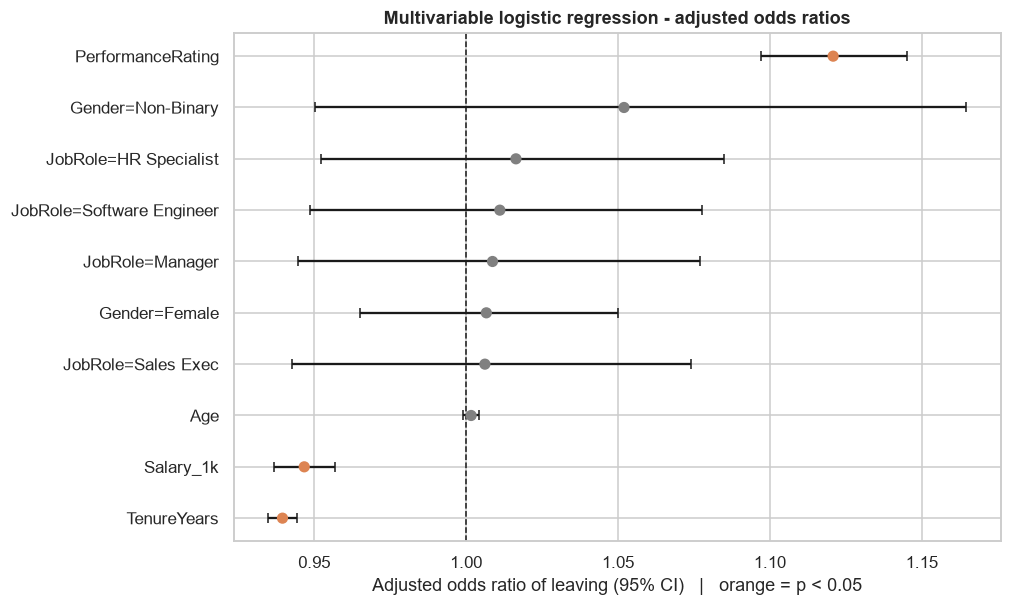

In [19]:
display(Image(str(sa.FIG_DIR / "05_logistic_odds_ratios.png")))

**Interpretation (adjusted odds ratios)**

| Feature | Adjusted OR (95 % CI) | Meaning |
|---|---|---|
| **TenureYears** | **0.940** (0.935–0.944) | each extra year lowers the odds of leaving by **6 %** (about 46 % lower over 10 years) |
| **Salary (+1,000)** | **0.947** (0.937–0.957) | each extra 1,000/month lowers the odds by **5.3 %** |
| **PerformanceRating (+1)** | **1.121** (1.097–1.145) | each extra rating point **raises** the odds by **12 %** |
| Age | 1.002 (0.999–1.004) | n.s. once tenure is controlled for |
| JobRole (any) | about 1.01 | n.s. (LR test p = 0.99) |
| Gender (any) | 1.01–1.05 | n.s. (LR test p = 0.62) |

- The likelihood-ratio tests confirm that **only tenure, salary and performance** add information (all p_holm < 0.001).
- **McFadden pseudo-R² = 0.016** means these features explain only a small part of who leaves. The effects are
  real, but most of the variation in attrition comes from factors **not in the dataset** (e.g. satisfaction, overtime,
  manager quality). This sets realistic expectations for Milestone 3 models.

## 6. Summary of hypothesis tests

| Feature | Test(s) | Decision (α = 0.05, Holm) | Effect size | Direction |
|---|---|---|---|---|
| **TenureYears** | Welch t, MWU, χ², trend, logit | **Reject H₀** | small (d = −0.26, V = 0.11) | longer tenure → less attrition |
| **MonthlySalary** | Welch t, MWU, χ², trend, logit, stratified t | **Reject H₀** | negligible (d = −0.10) | higher pay → less attrition (except top performers) |
| **PerformanceRating** | Welch t, MWU, χ², trend, logit | **Reject H₀** | negligible (d = 0.11) | higher rating → **more** attrition |
| **JobRole** | χ², two-way ANOVA, logit LR | **Fail to reject** | none (V = 0.002) | no effect |
| Gender | χ², logit LR | **Fail to reject** | none | no effect |
| Age | Welch t, MWU, logit | **Fail to reject** (adjusted) | none | no effect |
| Salary ↔ Performance | One-way ANOVA, Tukey | **Fail to reject** | η² ≈ 0 | **pay is not linked to performance** |
| Salary ↔ JobRole | One-way ANOVA | **Fail to reject** | η² ≈ 0 | same pay across roles |

**Recommendations for Task 2 (feature engineering) and Milestone 3**
1. Keep **TenureYears, MonthlySalary, PerformanceRating**; candidates to **drop**: JobRole, Gender (also good for fairness), Age.
2. Add a **Salary × Performance interaction** (supported by the significant two-way ANOVA interaction) and tenure bands.
3. Expect modest model performance (pseudo-R² = 0.016). Prioritise recall/ROC-AUC and consider tree ensembles that can pick up interactions.